# B2 — DDR

Train-only inverse square root class weighting, normalized to mean image weight one, may improve minority recognition. This separate arm starts from the unaugmented B0 protocol.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

Exact recorded main training module matched by SHA-256 to [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/3a563c67fef82454ce2ed34858615bd456424a13/novelty/foundation_adaptation.py). The optional CLI uses the current [foundation adaptation](../../novelty/foundation_adaptation.py) for a separately recorded new run.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B2', 'DDR'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = 'b45d8c30b1657edb3b7f29a0c0e28db90aa371fce655b5f2618fd915f3567f93'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B2 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | sum_i weight[label_i]*CE_i / actual window image count; validation ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 7bc3e3916e012bc46fcd9cd69aa469e0daf3229e1273f1d8ecb6054899bf6eb1 |
| train / validation counts | {'train': 10018, 'val': 1252} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": "none; deterministic official processor for train and validation",
  "class_weighting": {
    "formula": "w_c=(n_c^-0.5)/(sum_j n_j*n_j^-0.5 / N_train)",
    "train_counts": [
      5014,
      504,
      3581,
      189,
      730
    ],
    "weights": [
      0.7297673426617228,
      2.301766797811434,
      0.8635240327782341,
      3.7587694410119923,
      1.912560400091831
    ]
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.984013 | 0.709822 | 0.4406 | 0.686234 | 0.671055 | 0.525953 |
| 2 | 0.74597 | 0.778399 | 0.585616 | 0.770119 | 0.79382 | 0.365143 |
| 3 | 0.642792 | 0.809343 | 0.642063 | 0.804526 | 0.831306 | 0.303454 |
| 4 | 0.550164 | 0.833799 | 0.692398 | 0.831754 | 0.861546 | 0.255939 |
| 5 | 0.452717 | 0.862547 | 0.749905 | 0.862197 | 0.890488 | 0.206828 |
| 6 | 0.368847 | 0.890996 | 0.809087 | 0.892438 | 0.915129 | 0.161709 |
| 7 | 0.282842 | 0.919245 | 0.86379 | 0.920263 | 0.937658 | 0.119086 |
| 8 | 0.195918 | 0.946995 | 0.912263 | 0.947534 | 0.958257 | 0.0791575 |
| 9 | 0.124706 | 0.969355 | 0.951834 | 0.969495 | 0.974148 | 0.0474147 |
| 10 | 0.0701664 | 0.984827 | 0.975705 | 0.9849 | 0.987685 | 0.0230585 |
| 11 | 0.0328546 | 0.993911 | 0.990133 | 0.993924 | 0.995219 | 0.00908365 |
| 12 | 0.0130066 | 0.997205 | 0.996179 | 0.997207 | 0.997499 | 0.00449191 |
| 13 | 0.00410298 | 0.999401 | 0.999356 | 0.999401 | 0.99943 | 0.000998203 |
| 14 | 0.00156525 | 0.999501 | 0.999404 | 0.999501 | 0.999557 | 0.000798563 |
| 15 | 0.000571042 | 0.9999 | 0.999774 | 0.9999 | 0.999968 | 9.98203e-05 |
| 16 | 0.000584544 | 0.9999 | 0.999774 | 0.9999 | 0.999968 | 9.98203e-05 |
| 17 | 0.00120925 | 0.9999 | 0.999774 | 0.9999 | 0.999968 | 9.98203e-05 |
| 18 | 0.000333215 | 0.9999 | 0.999774 | 0.9999 | 0.999968 | 9.98203e-05 |
| 19 | 0.000844951 | 0.9999 | 0.999773 | 0.9999 | 0.999968 | 9.98203e-05 |
| 20 | 0.00136638 | 0.9998 | 0.999547 | 0.9998 | 0.999937 | 0.000199641 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.685509 | 0.764377 | 0.54541 | 0.748837 | 0.757982 | 0.40016 |
| 2 | 0.621793 | 0.777157 | 0.589334 | 0.761339 | 0.778024 | 0.378594 |
| 3 | 0.638057 | 0.769169 | 0.593338 | 0.760935 | 0.793425 | 0.376997 |
| 4 | 0.611039 | 0.783546 | 0.613232 | 0.771401 | 0.793948 | 0.365016 |
| 5 | 0.658514 | 0.770767 | 0.623084 | 0.774761 | 0.800902 | 0.361022 |
| 6 | 0.71689 | 0.749201 | 0.607423 | 0.761915 | 0.788195 | 0.379393 |
| 7 | 0.659037 | 0.789936 | 0.611015 | 0.77942 | 0.788047 | 0.353834 |
| 8 | 0.703307 | 0.796326 | 0.622309 | 0.788724 | 0.801052 | 0.335463 |
| 9 | 0.818537 | 0.78115 | 0.600103 | 0.776098 | 0.788718 | 0.357029 |
| 10 | 0.914951 | 0.792332 | 0.609026 | 0.785194 | 0.803338 | 0.334665 |
| 11 | 1.05565 | 0.785144 | 0.605892 | 0.783647 | 0.813634 | 0.333067 |
| 12 | 1.23074 | 0.789137 | 0.583603 | 0.781903 | 0.812347 | 0.332268 |
| 13 | 1.37493 | 0.798722 | 0.604048 | 0.788316 | 0.81367 | 0.325879 |
| 14 | 1.49895 | 0.795527 | 0.59429 | 0.786876 | 0.81489 | 0.326677 |
| 15 | 1.56475 | 0.805112 | 0.614226 | 0.794486 | 0.820622 | 0.314696 |
| 16 | 1.58504 | 0.803514 | 0.615025 | 0.794761 | 0.824887 | 0.3123 |
| 17 | 1.62587 | 0.801118 | 0.61129 | 0.79151 | 0.820801 | 0.317891 |
| 18 | 1.64828 | 0.796326 | 0.604986 | 0.787205 | 0.81609 | 0.325879 |
| 19 | 1.68904 | 0.797923 | 0.59113 | 0.787192 | 0.818866 | 0.321885 |
| 20 | 1.70152 | 0.799521 | 0.609088 | 0.790332 | 0.821423 | 0.31869 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 50.449 | 2.86788 | 9.87726 | 1.21762 | 198.577 | 436.56 | 2688548864 | 1615822848 | 164 | 131 | 6 |
| 2 | 50.3755 | 2.869 | 10.1469 | 1.22296 | 198.866 | 436.39 | 2688548864 | 1622437888 | 155 | 124 | 14 |
| 3 | 50.7098 | 2.92072 | 10.2781 | 1.2638 | 197.556 | 428.662 | 2688548864 | 1622446080 | 143 | 146 | 22 |
| 4 | 50.5948 | 2.91992 | 10.2389 | 1.25349 | 198.005 | 428.779 | 2688548864 | 1622700032 | 152 | 119 | 39 |
| 5 | 50.7398 | 2.89821 | 10.3009 | 1.2402 | 197.439 | 431.991 | 2688548864 | 1622892544 | 110 | 177 | 37 |
| 6 | 50.5471 | 2.90406 | 10.1513 | 1.24861 | 198.191 | 431.12 | 2688548864 | 1622986752 | 115 | 199 | 45 |
| 7 | 50.6997 | 2.90322 | 10.1634 | 1.25072 | 197.595 | 431.245 | 2688548864 | 1622986752 | 122 | 141 | 72 |
| 8 | 50.6845 | 2.89046 | 10.2026 | 1.23222 | 197.654 | 433.149 | 2688548864 | 1622986752 | 130 | 125 | 88 |
| 9 | 50.729 | 2.90104 | 10.2631 | 1.24501 | 197.481 | 431.57 | 2688548864 | 1622986752 | 131 | 143 | 112 |
| 10 | 50.5561 | 2.91964 | 10.1627 | 1.26102 | 198.156 | 428.82 | 2688548864 | 1622986752 | 132 | 128 | 131 |
| 11 | 50.7597 | 2.93258 | 10.2803 | 1.26529 | 197.361 | 426.928 | 2688548864 | 1622986752 | 153 | 116 | 141 |
| 12 | 50.796 | 2.93196 | 10.351 | 1.26706 | 197.22 | 427.018 | 2688548864 | 1622986752 | 162 | 102 | 150 |
| 13 | 50.7552 | 2.93619 | 10.2257 | 1.2745 | 197.379 | 426.403 | 2688548864 | 1623015424 | 142 | 110 | 170 |
| 14 | 50.8064 | 2.9093 | 10.3045 | 1.25213 | 197.18 | 430.344 | 2688548864 | 1623068672 | 124 | 132 | 178 |
| 15 | 50.7013 | 2.94176 | 10.2279 | 1.27772 | 197.589 | 425.596 | 2688548864 | 1623068672 | 125 | 119 | 175 |
| 16 | 50.0127 | 2.94044 | 9.79783 | 1.28327 | 200.309 | 425.786 | 2688548864 | 1623412736 | 132 | 114 | 174 |
| 17 | 49.9819 | 2.84545 | 9.84355 | 1.22622 | 200.433 | 440.001 | 2688548864 | 1623412736 | 134 | 115 | 176 |
| 18 | 50.1137 | 2.83303 | 9.8919 | 1.21185 | 199.905 | 441.93 | 2688548864 | 1623703552 | 142 | 113 | 177 |
| 19 | 49.9757 | 2.85242 | 9.82512 | 1.22785 | 200.458 | 438.926 | 2688548864 | 1623810048 | 138 | 115 | 178 |
| 20 | 50.178 | 2.88743 | 10.0171 | 1.26279 | 199.649 | 433.603 | 2688548864 | 1623810048 | 138 | 113 | 179 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 5 | True |
| 6 | 1e-05 | 0.001 | — | 5 | False |
| 7 | 1e-05 | 0.001 | — | 5 | False |
| 8 | 1e-05 | 0.001 | — | 5 | False |
| 9 | 1e-05 | 0.001 | — | 5 | False |
| 10 | 1e-05 | 0.001 | — | 5 | False |
| 11 | 1e-05 | 0.001 | — | 5 | False |
| 12 | 1e-05 | 0.001 | — | 5 | False |
| 13 | 1e-05 | 0.001 | — | 5 | False |
| 14 | 1e-05 | 0.001 | — | 5 | False |
| 15 | 1e-05 | 0.001 | — | 5 | False |
| 16 | 1e-05 | 0.001 | — | 5 | False |
| 17 | 1e-05 | 0.001 | — | 5 | False |
| 18 | 1e-05 | 0.001 | — | 5 | False |
| 19 | 1e-05 | 0.001 | — | 5 | False |
| 20 | 1e-05 | 0.001 | — | 5 | False |

## B2 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.770767 | 0.623084 | 0.774761 | 0.800902 | 0.361022 | 965 | 287 | 110 | 177 |

Frozen validation only. The selected checkpoint SHA-256 is `b45d8c30b1657edb3b7f29a0c0e28db90aa371fce655b5f2618fd915f3567f93`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 522 | 29 | 73 | 0 | 2 |
| 1 | 14 | 16 | 32 | 0 | 1 |
| 2 | 48 | 23 | 341 | 17 | 19 |
| 3 | 0 | 0 | 5 | 15 | 4 |
| 4 | 0 | 0 | 17 | 3 | 71 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 83.3866 | 4.63259 | 11.6613 | 0 | 0.319489 |
| 1 | 22.2222 | 25.3968 | 50.7937 | 0 | 1.5873 |
| 2 | 10.7143 | 5.13393 | 76.1161 | 3.79464 | 4.24107 |
| 3 | 0 | 0 | 20.8333 | 62.5 | 16.6667 |
| 4 | 0 | 0 | 18.6813 | 3.2967 | 78.022 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.893836 | 0.833866 | 0.86281 | 626 | 522 |
| 1 | 0.235294 | 0.253968 | 0.244275 | 63 | 16 |
| 2 | 0.728632 | 0.761161 | 0.744541 | 448 | 341 |
| 3 | 0.428571 | 0.625 | 0.508475 | 24 | 15 |
| 4 | 0.731959 | 0.78022 | 0.755319 | 91 | 71 |

Minority-grade predictions on the diagonal were grade 1 16/63, grade 3 15/24. The largest off-diagonal counts were 0 → 2 (73), 2 → 0 (48), 1 → 2 (32). The matrix gives 127 adjacent errors and 160 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/DDR_B2_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/DDR_B2_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

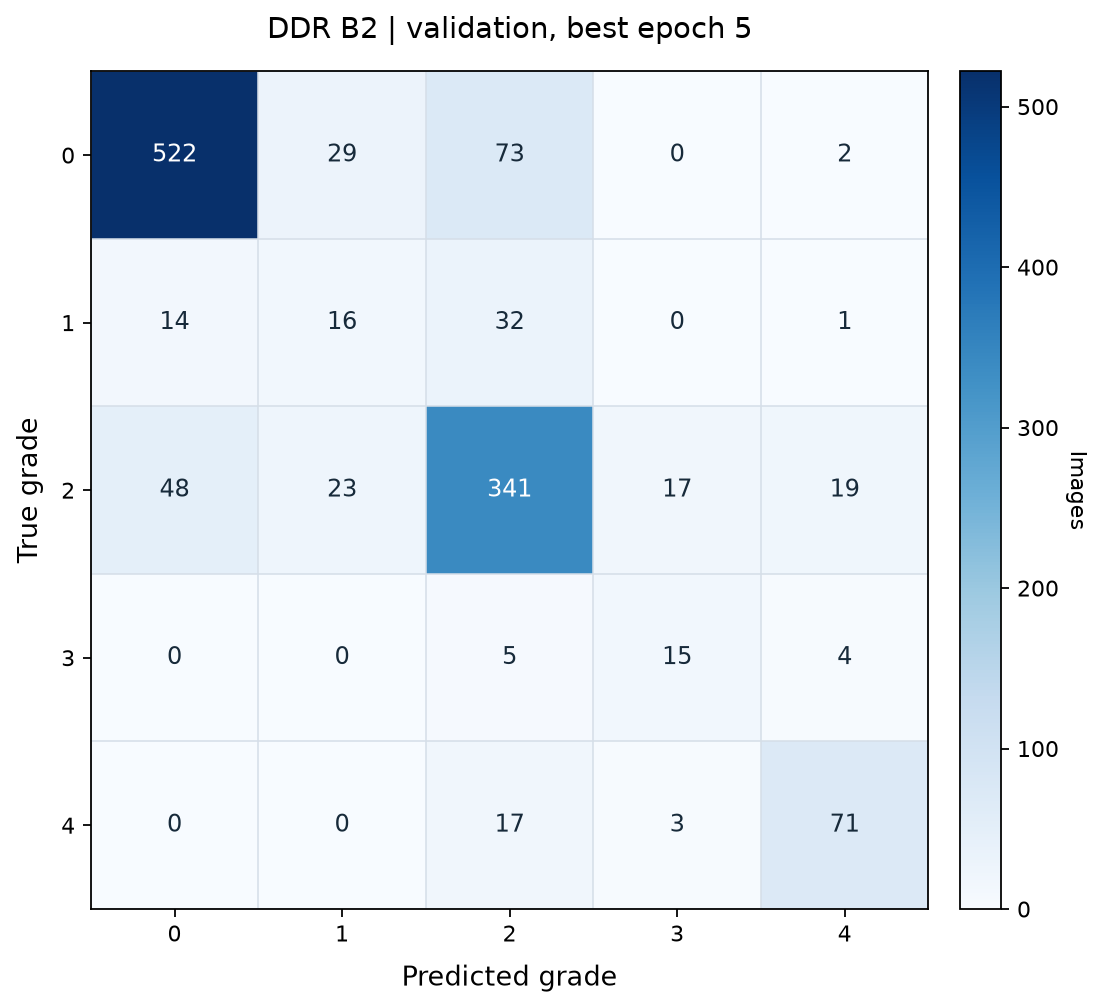

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B2_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

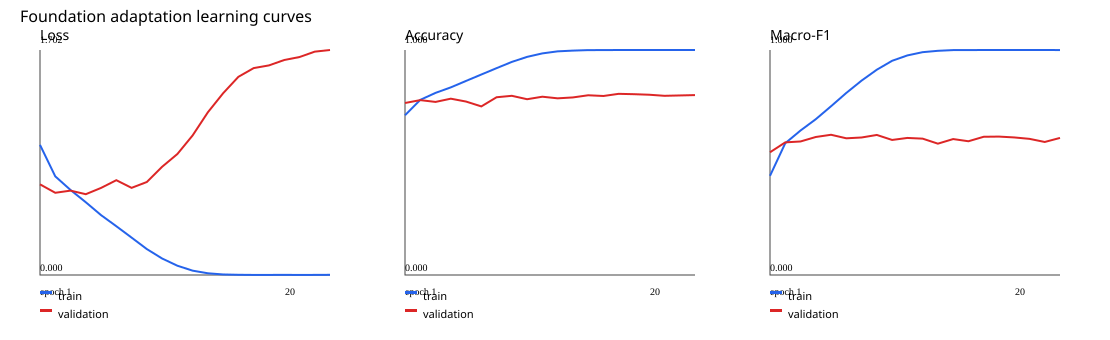

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/DDR_B2_learning_curves.svg')))

## Interpretation and limits

Compared with B0 on this validation split, macro-F1 changed by +0.003267, grade 1 recall by +0.1746, and grade 3 recall by +0.0000.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})